# Прекод

# Сборный проект-5

Вам поручено разработать демонстрационную версию поиска изображений по запросу.

Для демонстрационной версии нужно обучить модель, которая получит векторное представление изображения, векторное представление текста, а на выходе выдаст число от 0 до 1 — покажет, насколько текст и картинка подходят друг другу.

### Описание данных

Данные доступны по [ссылке](https://code.s3.yandex.net/datasets/dsplus_integrated_project_4.zip).

В файле `train_dataset.csv` находится информация, необходимая для обучения: имя файла изображения, идентификатор описания и текст описания. Для одной картинки может быть доступно до 5 описаний. Идентификатор описания имеет формат `<имя файла изображения>#<порядковый номер описания>`.

В папке `train_images` содержатся изображения для тренировки модели.

В файле `CrowdAnnotations.tsv` — данные по соответствию изображения и описания, полученные с помощью краудсорсинга. Номера колонок и соответствующий тип данных:

1. Имя файла изображения.
2. Идентификатор описания.
3. Доля людей, подтвердивших, что описание соответствует изображению.
4. Количество человек, подтвердивших, что описание соответствует изображению.
5. Количество человек, подтвердивших, что описание не соответствует изображению.

В файле `ExpertAnnotations.tsv` содержатся данные по соответствию изображения и описания, полученные в результате опроса экспертов. Номера колонок и соответствующий тип данных:

1. Имя файла изображения.
2. Идентификатор описания.

3, 4, 5 — оценки трёх экспертов.

Эксперты ставят оценки по шкале от 1 до 4, где 1 — изображение и запрос совершенно не соответствуют друг другу, 2 — запрос содержит элементы описания изображения, но в целом запрос тексту не соответствует, 3 — запрос и текст соответствуют с точностью до некоторых деталей, 4 — запрос и текст соответствуют полностью.

В файле `test_queries.csv` находится информация, необходимая для тестирования: идентификатор запроса, текст запроса и релевантное изображение. Для одной картинки может быть доступно до 5 описаний. Идентификатор описания имеет формат `<имя файла изображения>#<порядковый номер описания>`.

В папке `test_images` содержатся изображения для тестирования модели.

<div class="alert alert-info"> Уважаемый ревьюер! В попытках успеть все я немного не успел уложиться в дедлайн и у меня сборный проект 5 накладывается на выпускной проект. Сейчас в проекте сделано все, кроме обучения полносвязной нейронной сети. Проверь, пожалуйста, пока без нее. На следующую итерацию уже будет все сделано. Надеюсь, что так тебе получится быстрее проверить мой проект, а мне быстрее его сдать. С куратором небольшую задержку сдачи проекта согласовал. Спасибо!</div>

## 1. Исследовательский анализ данных

Наш датасет содержит экспертные и краудсорсинговые оценки соответствия текста и изображения.

В файле с экспертными мнениями для каждой пары изображение-текст имеются оценки от трёх специалистов. 

В файле с краудсорсинговыми оценками информация расположена в таком порядке:

1. Доля исполнителей, подтвердивших, что текст **соответствует** картинке.
2. Количество исполнителей, подтвердивших, что текст **соответствует** картинке.
3. Количество исполнителей, подтвердивших, что текст **не соответствует** картинке.

In [95]:
# установка необходимых библиотек

!pip install --upgrade scikit-learn -q
# !pip install phik -q
!pip install tensorflow -q
!pip install torch -q
!pip install torchvision -q
!pip install transformers -q

  You can safely remove it manually.


In [1]:
# импортируем необходимые для работы библиотеки

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
import re

pd.options.display.float_format = '{:,.3f}'.format

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from PIL import Image

from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import torchvision.models as models
from torch.utils.data import DataLoader,Dataset
import torchvision.transforms as T

from tqdm.auto import tqdm

from transformers import AutoTokenizer, AutoModel

from sklearn.model_selection import GroupShuffleSplit, KFold, GridSearchCV

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import  Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity


In [2]:
# объявления констант

RANDOM_STATE = 42
expert_part = 0.7
crowd_part = 0.3

In [3]:
# изменим стиль отображения графиков и таблиц

mpl.style.use(['ggplot'])
pd.set_option('display.max_colwidth', 300)

**Загрузим данные. И начнем мы с текстовых**

In [4]:
expert_df = pd.read_csv('to_upload/ExpertAnnotations.tsv', sep='\t', names=['image', 'query_id', 'expert_1', 'expert_2', 'expert_3'])
expert_df.head(10)

,image,query_id,expert_1,expert_2,expert_3
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2
5,1056338697_4f7d7ce270.jpg,3360930596_1e75164ce6.jpg#2,1,1,1
6,1056338697_4f7d7ce270.jpg,3545652636_0746537307.jpg#2,1,1,1
7,1056338697_4f7d7ce270.jpg,434792818_56375e203f.jpg#2,1,1,2
8,106490881_5a2dd9b7bd.jpg,1425069308_488e5fcf9d.jpg#2,1,1,1
9,106490881_5a2dd9b7bd.jpg,1714316707_8bbaa2a2ba.jpg#2,2,2,2


In [5]:
expert_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image     5822 non-null   object
 1   query_id  5822 non-null   object
 2   expert_1  5822 non-null   int64 
 3   expert_2  5822 non-null   int64 
 4   expert_3  5822 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 227.6+ KB


In [6]:
len(expert_df['query_id'].unique())

977

In [7]:
len(expert_df['image'].unique())

1000

**1000 уникальных картинок было рассмотрено экспертами**

In [8]:
crowd_df = pd.read_csv('to_upload/CrowdAnnotations.tsv', sep='\t', names=['image', 'query_id', 'part', 'approve', 'not_approve'])
crowd_df.head(10)

,image,query_id,part,approve,not_approve
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.000,3,0
1,1056338697_4f7d7ce270.jpg,114051287_dd85625a04.jpg#2,0.000,0,3
2,1056338697_4f7d7ce270.jpg,1427391496_ea512cbe7f.jpg#2,0.000,0,3
3,1056338697_4f7d7ce270.jpg,2073964624_52da3a0fc4.jpg#2,0.000,0,3
4,1056338697_4f7d7ce270.jpg,2083434441_a93bc6306b.jpg#2,0.000,0,3
5,1056338697_4f7d7ce270.jpg,2204550058_2707d92338.jpg#2,0.000,0,3
6,1056338697_4f7d7ce270.jpg,2224450291_4c133fabe8.jpg#2,0.000,0,3
7,1056338697_4f7d7ce270.jpg,2248487950_c62d0c81a9.jpg#2,0.333,1,2
8,1056338697_4f7d7ce270.jpg,2307118114_c258e3a47e.jpg#2,0.000,0,3
9,1056338697_4f7d7ce270.jpg,2309860995_c2e2a0feeb.jpg#2,0.000,0,3


In [9]:
crowd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47830 entries, 0 to 47829
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   image        47830 non-null  object 
 1   query_id     47830 non-null  object 
 2   part         47830 non-null  float64
 3   approve      47830 non-null  int64  
 4   not_approve  47830 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 1.8+ MB


In [10]:
len(crowd_df['query_id'].unique())

1000

In [11]:
len(crowd_df['image'].unique())

1000

**1000 уникальных картинок было оценено в опросах. При этом, как видно из количества строк и шапок датасета, в опросах у картинок было гораздо больше вариантов описаний**

In [12]:
expert_df['query_id'].value_counts()

query_id
2600867924_cd502fc911.jpg#2    34
1554713437_61b64527dd.jpg#2    27
2522297487_57edf117f7.jpg#2    25
1536774449_e16b1b6382.jpg#2    25
3593392955_a4125087f6.jpg#2    22
                               ..
2594902417_f65d8866a8.jpg#2     1
3592992234_6d3fe58a70.jpg#2     1
2757803246_8aa3499d26.jpg#2     1
3085667865_fa001816be.jpg#2     1
2292406847_f366350600.jpg#2     1
Name: count, Length: 977, dtype: int64

In [13]:
crowd_df['query_id'].value_counts()

query_id
249394748_2e4acfbbb5.jpg#2     169
820169182_f5e78d7d19.jpg#2     150
500446858_125702b296.jpg#2     149
2869491449_1041485a6b.jpg#2    143
327415627_6313d32a64.jpg#2     139
                              ... 
3191135894_2b4bdabb6d.jpg#2      9
3584561689_b6eb24dd70.jpg#2      7
3042380610_c5ea61eef8.jpg#2      7
1547883892_e29b3db42e.jpg#2      7
3197981073_3156963446.jpg#2      6
Name: count, Length: 1000, dtype: int64

**Надо как-то объеденить два датасета с разным количеством описаний к каждой конкретной картинке.**

**При этом уникальных описаний в экспертной выборке 977, тогда как в опросе их было 1000**

In [14]:
train_df_chld = pd.read_csv('to_upload/train_dataset.csv', sep=',')
train_df_chld.head(10)

,image,query_id,query_text
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
1,1262583859_653f1469a9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
2,2447284966_d6bbdb4b6e.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
3,2549968784_39bfbe44f9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
4,2621415349_ef1a7e73be.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
5,3030566410_393c36a6c5.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
6,3155451946_c0862c70cb.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
7,3222041930_f642f49d28.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
8,343218198_1ca90e0734.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
9,3718964174_cb2dc1615e.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .


In [15]:
train_df_chld.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image       5822 non-null   object
 1   query_id    5822 non-null   object
 2   query_text  5822 non-null   object
dtypes: object(3)
memory usage: 136.6+ KB


In [16]:
len(train_df_chld['image'].unique())

1000

**Тоже 1000 картинок**

In [17]:
train_df_chld[train_df_chld['image'] == '2549968784_39bfbe44f9.jpg']

,image,query_id,query_text
3,2549968784_39bfbe44f9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
4160,2549968784_39bfbe44f9.jpg,2490768374_45d94fc658.jpg#2,a young girl wearing blue smiles .
5134,2549968784_39bfbe44f9.jpg,2384353160_f395e9a54b.jpg#2,An older man in a weathered fedora smiles slightly for the camera .
5137,2549968784_39bfbe44f9.jpg,3532205154_5674b628ea.jpg#2,A man with a shocked expression on his face is holding a beaded necklace that is around a woman 's neck .


**На примере одной картинки видим, насколько разное может быть ее описание. Одни говорят, что на картинке дед, другие - что ребенок (там ребенок)**

In [18]:
test_img = pd.read_csv('to_upload/test_images.csv')
test_img.head()

,image
0,3356748019_2251399314.jpg
1,2887171449_f54a2b9f39.jpg
2,3089107423_81a24eaf18.jpg
3,1429546659_44cb09cbe2.jpg
4,1177994172_10d143cb8d.jpg


In [19]:
test_img.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   image   100 non-null    object
dtypes: object(1)
memory usage: 932.0+ bytes


**Тестовых картинок 100 штук**

In [20]:
test_qr = pd.read_csv('to_upload/test_queries.csv', sep='|', index_col=0)
test_qr.head(10)

,query_id,query_text,image
0,1177994172_10d143cb8d.jpg#0,"Two blonde boys , one in a camouflage shirt and the other in blue , are having a water fight .",1177994172_10d143cb8d.jpg
1,1177994172_10d143cb8d.jpg#1,Two boys are squirting water guns at each other .,1177994172_10d143cb8d.jpg
2,1177994172_10d143cb8d.jpg#2,Two boys spraying each other with water,1177994172_10d143cb8d.jpg
3,1177994172_10d143cb8d.jpg#3,Two children wearing jeans squirt water at each other .,1177994172_10d143cb8d.jpg
4,1177994172_10d143cb8d.jpg#4,Two young boys are squirting water at each other .,1177994172_10d143cb8d.jpg
5,1232148178_4f45cc3284.jpg#0,A baby girl playing at a park .,1232148178_4f45cc3284.jpg
6,1232148178_4f45cc3284.jpg#1,A closeup of a child on a playground with adult supervision .,1232148178_4f45cc3284.jpg
7,1232148178_4f45cc3284.jpg#2,A young boy poses for a picture in front of a playground .,1232148178_4f45cc3284.jpg
8,1232148178_4f45cc3284.jpg#3,A young girl is smiling in front of the camera at a park .,1232148178_4f45cc3284.jpg
9,1232148178_4f45cc3284.jpg#4,There is a little blond hair girl with a green sweatshirt and a red shirt playing on a playground .,1232148178_4f45cc3284.jpg


In [21]:
test_qr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   query_id    500 non-null    object
 1   query_text  500 non-null    object
 2   image       500 non-null    object
dtypes: object(3)
memory usage: 15.6+ KB


In [22]:
len(test_qr['image'].unique())

100

**В тестовом датасете 500 описаний к 100 картинкам**

**Текстовые данные загружены. Сильно путают id описаний, названные по имени картинки. И еще нужно проверить, есть ли в файлах с оценками картинки из тестовой выборки.**

In [23]:
mask_tt = test_qr['image'].isin(train_df_chld['image'])

print(f"Совпадений: {mask_tt.sum()} из {len(test_qr['image'])}")

Совпадений: 0 из 500


In [24]:
mask_t_img = test_qr['image'].isin(test_img['image'])

print(f"Совпадений: {mask_t_img.sum()} из {len(test_qr['image'])}")

Совпадений: 500 из 500


**Отлично, в тренировочном и тестовом датасетах картинки разные. А в тестоовых датасетах для всех картинок есть описания, точность которых еще предстоит определить**

**Теперь нужно поработать с датасетами с оценками. Попробуем сделать составную оценку из экспертов и опросов. Но для этого нужно, чтобы оценки были к одному и тому же описанию. А мы видели, что описаний, оцененых опросами гораздо больше. Нужно сделать сборный датасет из названий картинок и описаний, которые оценивали и эксперты и опросы. Объединять датасеты будем по ключу, состоящему из названия картинки и id описания.**

In [25]:
expert_df['key'] = expert_df['image'] + '_' + expert_df['query_id']
expert_df.head(1)

,image,query_id,expert_1,expert_2,expert_3,key
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1,1056338697_4f7d7ce270.jpg_2549968784_39bfbe44f9.jpg#2


In [26]:
crowd_df['key'] = crowd_df['image'] + '_' + crowd_df['query_id']
crowd_df.head(1)

,image,query_id,part,approve,not_approve,key
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.000,3,0,1056338697_4f7d7ce270.jpg_1056338697_4f7d7ce270.jpg#2


In [27]:
general_df = expert_df.merge(crowd_df.drop(columns=['image', 'query_id']), how='left', on='key')
general_df.head()

,image,query_id,expert_1,expert_2,expert_3,key,part,approve,not_approve
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1,1056338697_4f7d7ce270.jpg_2549968784_39bfbe44f9.jpg#2,0.000,0.000,3.000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_2718495608_d8533e3ac5.jpg#2,0.000,0.000,3.000
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_3181701312_70a379ab6e.jpg#2,NaN,NaN,NaN
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2,1056338697_4f7d7ce270.jpg_3207358897_bfa61fa3c6.jpg#2,NaN,NaN,NaN
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_3286822339_5535af6b93.jpg#2,NaN,NaN,NaN


In [28]:
general_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   image        5822 non-null   object 
 1   query_id     5822 non-null   object 
 2   expert_1     5822 non-null   int64  
 3   expert_2     5822 non-null   int64  
 4   expert_3     5822 non-null   int64  
 5   key          5822 non-null   object 
 6   part         2329 non-null   float64
 7   approve      2329 non-null   float64
 8   not_approve  2329 non-null   float64
dtypes: float64(3), int64(3), object(3)
memory usage: 409.5+ KB


**В опросах присутствует меньше половины экспертных сочетаний картинок и описаний. Доверимся экспертам и оставим их всех в датасете**

**Сначала выведем общую экспертную оценку по каждой паре. Небольшое пояснение к расчету. Оценка "1" - полностью не соответствует, значит при переводе в систему оценки от 0 до 1 это будет 0. Оценки идут от 1 до 4. Изменение оценки происходит в интервале (4-1)=3. Поэтому я из суммы оценок вычитаю 3 (обнуляю единички) и эту сумму делю на 3*3 (3 оценки * 3 максимальные значения оценки), чтобы вычислить долю.**

In [29]:
general_df['expert_fin'] = np.where((general_df['expert_1'] == 1) & (general_df['expert_2'] == 1) & (general_df['expert_3'] == 1),
                                    0,
                                    round((general_df['expert_1'] +  general_df['expert_2'] +  general_df['expert_3'] - 3)/(3*3), 2))
general_df.head()

,image,query_id,expert_1,expert_2,expert_3,key,part,approve,not_approve,expert_fin
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1,1056338697_4f7d7ce270.jpg_2549968784_39bfbe44f9.jpg#2,0.000,0.000,3.000,0.000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_2718495608_d8533e3ac5.jpg#2,0.000,0.000,3.000,0.110
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_3181701312_70a379ab6e.jpg#2,NaN,NaN,NaN,0.110
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2,1056338697_4f7d7ce270.jpg_3207358897_bfa61fa3c6.jpg#2,NaN,NaN,NaN,0.220
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_3286822339_5535af6b93.jpg#2,NaN,NaN,NaN,0.110


**Теперь сравним ее с опросами**

In [30]:
general_proba = general_df.dropna()
general_proba = general_proba.head(150)
general_proba.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 0 to 426
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   image        150 non-null    object 
 1   query_id     150 non-null    object 
 2   expert_1     150 non-null    int64  
 3   expert_2     150 non-null    int64  
 4   expert_3     150 non-null    int64  
 5   key          150 non-null    object 
 6   part         150 non-null    float64
 7   approve      150 non-null    float64
 8   not_approve  150 non-null    float64
 9   expert_fin   150 non-null    float64
dtypes: float64(4), int64(3), object(3)
memory usage: 12.9+ KB


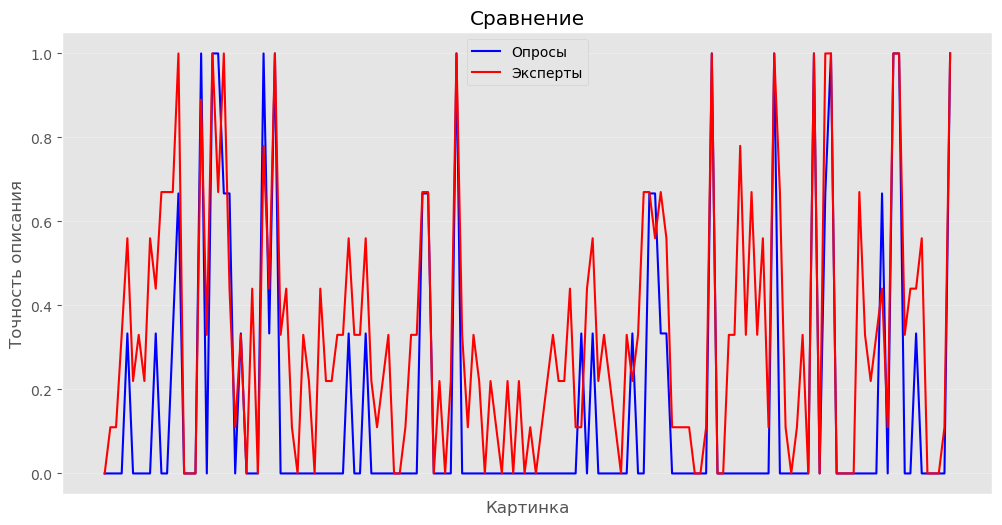

In [31]:
plt.figure(figsize=(12, 6))
plt.plot(general_proba['key'], general_proba['part'], label='Опросы', color='blue')
plt.plot(general_proba['key'], general_proba['expert_fin'], label='Эксперты', color='red')
plt.xlabel('Картинка')
plt.ylabel('Точность описания')
plt.title('Сравнение')
plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks([])
plt.show()

**Видим, что опросы и эксперты практически полностью солидарны при назначении оценки "полностью соответствует" паре картинка-описание. В других оценках тоже прослеживается закономерность, но лучше всего это видно на самых высоких оценках. Сначала удалим картинки, для которых эксперты не сошлись в оценке - нет одинаковой оценки у двух любых экспертов. Затем создадим общую оценку на основе этих двух. Причем доля экспертности в этой оценке будет 0.7, а доля опросов - 0.3.**

In [32]:
general_df['dummy'] = general_df[['expert_1', 'expert_2', 'expert_3']].nunique(axis=1)
general_df = general_df[general_df['dummy'] < 3].drop('dummy', axis=1)
general_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5696 entries, 0 to 5821
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   image        5696 non-null   object 
 1   query_id     5696 non-null   object 
 2   expert_1     5696 non-null   int64  
 3   expert_2     5696 non-null   int64  
 4   expert_3     5696 non-null   int64  
 5   key          5696 non-null   object 
 6   part         2258 non-null   float64
 7   approve      2258 non-null   float64
 8   not_approve  2258 non-null   float64
 9   expert_fin   5696 non-null   float64
dtypes: float64(4), int64(3), object(3)
memory usage: 489.5+ KB


In [33]:
general_df['rating'] = np.where(general_df['part'].isna(),
                                general_df['expert_fin'],
                                round(general_df['expert_fin']*expert_part + general_df['part']*crowd_part, 2))
general_df.head()

,image,query_id,expert_1,expert_2,expert_3,key,part,approve,not_approve,expert_fin,rating
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1,1056338697_4f7d7ce270.jpg_2549968784_39bfbe44f9.jpg#2,0.000,0.000,3.000,0.000,0.000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_2718495608_d8533e3ac5.jpg#2,0.000,0.000,3.000,0.110,0.080
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_3181701312_70a379ab6e.jpg#2,NaN,NaN,NaN,0.110,0.110
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2,1056338697_4f7d7ce270.jpg_3207358897_bfa61fa3c6.jpg#2,NaN,NaN,NaN,0.220,0.220
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2,1056338697_4f7d7ce270.jpg_3286822339_5535af6b93.jpg#2,NaN,NaN,NaN,0.110,0.110


**Сравним на графике новую оценку с опросами и экспертами**

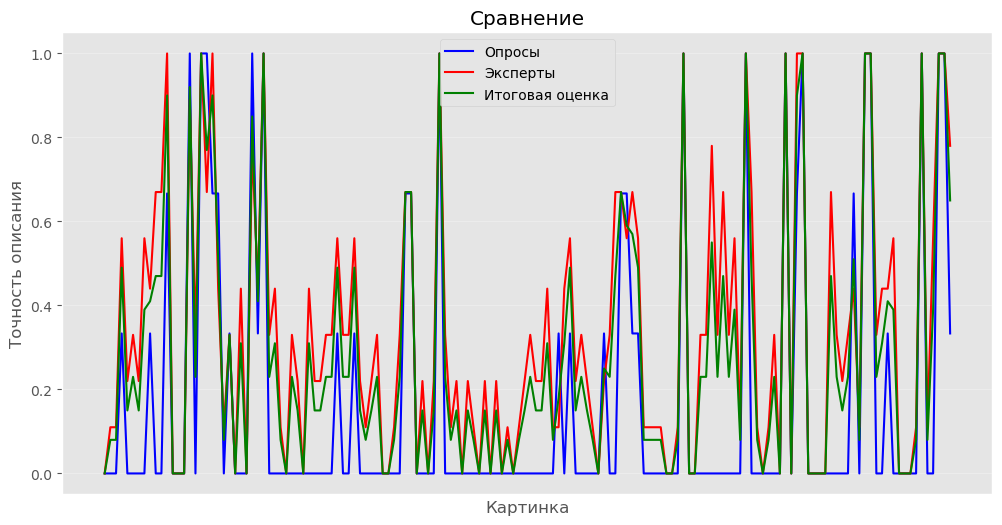

In [34]:
general_proba2 = general_df.dropna()
general_proba2 = general_proba2.head(150)

plt.figure(figsize=(12, 6))
plt.plot(general_proba2['key'], general_proba2['part'], label='Опросы', color='blue')
plt.plot(general_proba2['key'], general_proba2['expert_fin'], label='Эксперты', color='red')
plt.plot(general_proba2['key'], general_proba2['rating'], label='Итоговая оценка', color='green')
plt.xlabel('Картинка')
plt.ylabel('Точность описания')
plt.title('Сравнение')
plt.legend()
plt.grid(True, alpha=0.3)

plt.xticks([])
plt.show()

**Видно, как "подсползла" итоговая оценка относительно экспертной. Расчет итоговой оценки выполнен правильно.**

In [35]:
rating = general_df[['image', 'query_id', 'rating']]
rating.head()

,image,query_id,rating
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,0.000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,0.080
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,0.110
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,0.220
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,0.110


**Теперь посмотрим на картинки из обеих выборок**

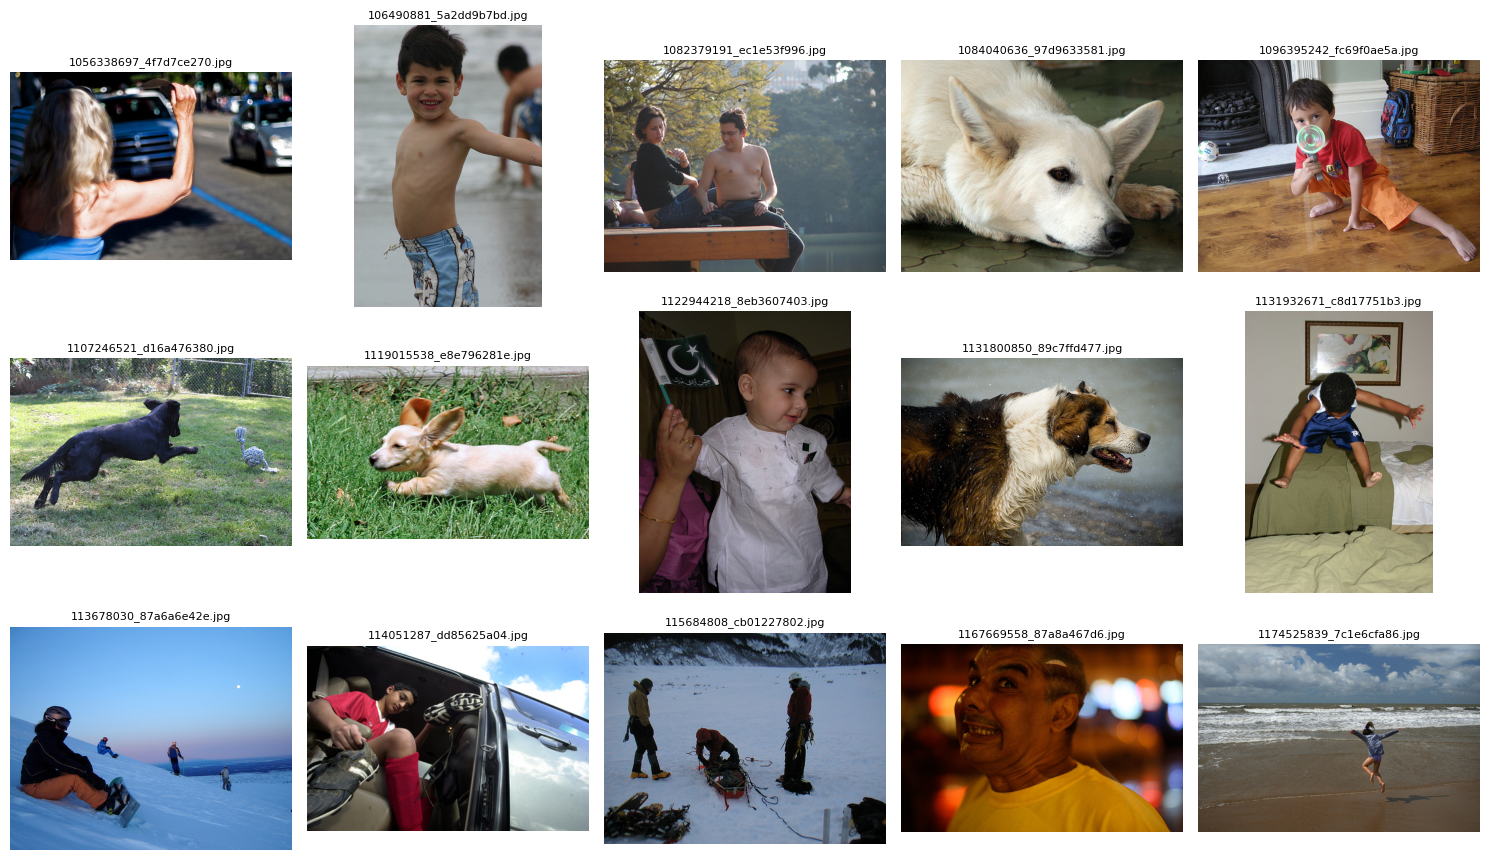

In [36]:
train_folder = Path('to_upload/train_images')
train_files = list(train_folder.glob('*.jpg'))

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, jpg in zip(axes.flat, train_files[:15]):
    image = Image.open(jpg)
    ax.imshow(np.array(image))
    ax.axis('off')
    ax.set_title(jpg.name, fontsize=8)
plt.tight_layout()
plt.show()

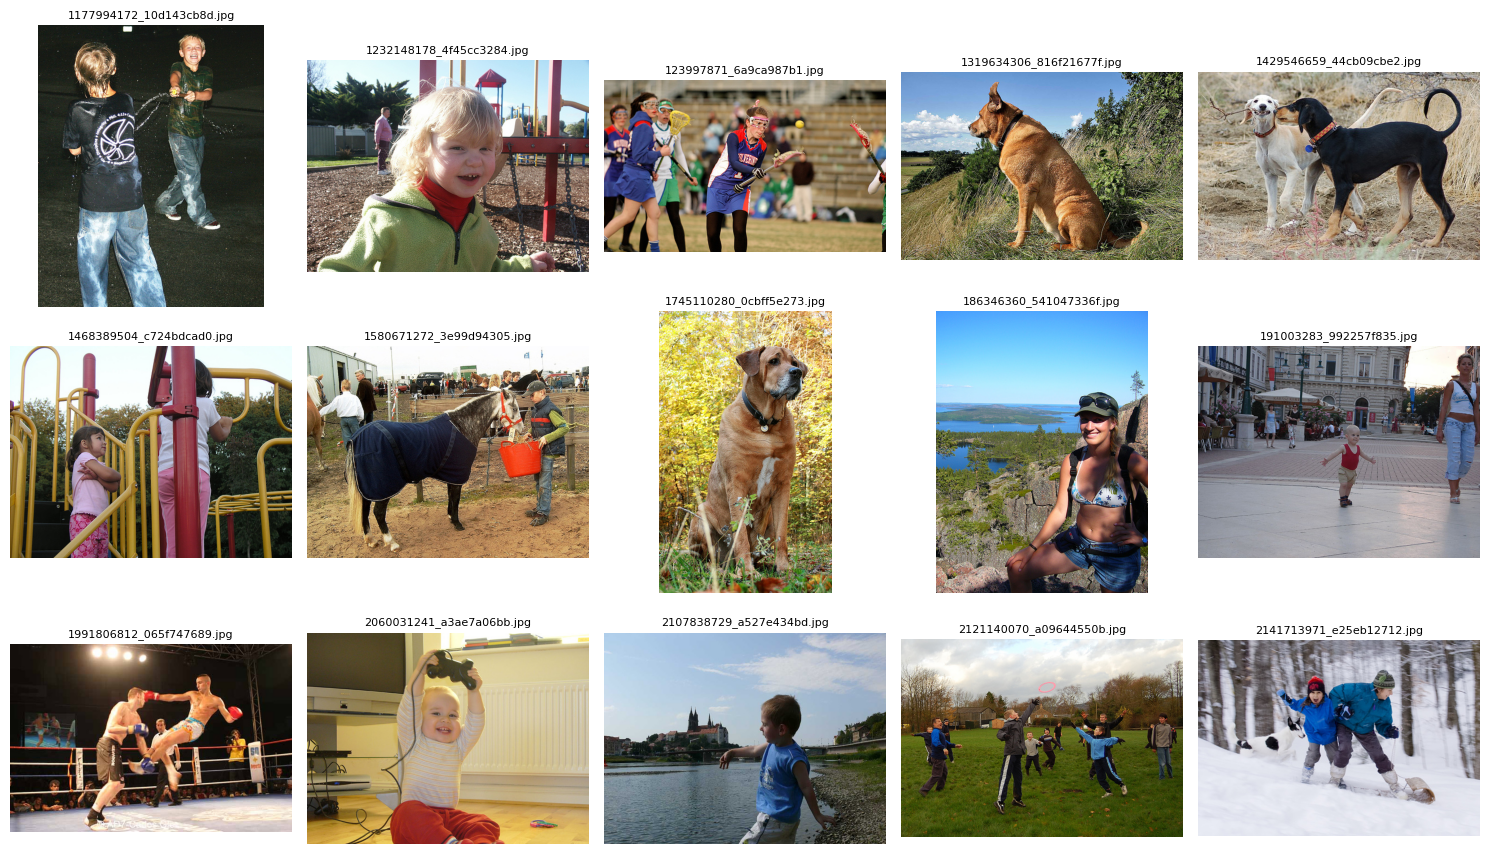

In [37]:
test_folder = Path('to_upload/test_images')
test_files = list(test_folder.glob('*.jpg'))

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, jpg in zip(axes.flat, test_files[:15]):
    image = Image.open(jpg)
    ax.imshow(np.array(image))
    ax.axis('off')
    ax.set_title(jpg.name, fontsize=8)
plt.tight_layout()
plt.show()

**В обеих папках есть картинки, в том числе с детьми.**

**Готово! Данные загружены, проанализированны и обработаны в части оценки соотвествия пары картинка-описание.**

## 2. Проверка данных

В некоторых странах, где работает ваша компания, действуют ограничения по обработке изображений: поисковым сервисам и сервисам, предоставляющим возможность поиска, запрещено без разрешения родителей или законных представителей предоставлять любую информацию, в том числе, но не исключительно тексты, изображения, видео и аудио, содержащие описание, изображение или запись голоса детей. Ребёнком считается любой человек, не достигший 16 лет.

В вашем сервисе строго следуют законам стран, в которых работают. Поэтому при попытке посмотреть изображения, запрещённые законодательством, вместо картинок показывается дисклеймер:

> This image is unavailable in your country in compliance with local laws
>

Однако у вас в PoC нет возможности воспользоваться данным функционалом. Поэтому все изображения, которые нарушают данный закон, нужно удалить из обучающей выборки.

In [38]:
train_df_chld.head()

,image,query_id,query_text
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
1,1262583859_653f1469a9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
2,2447284966_d6bbdb4b6e.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
3,2549968784_39bfbe44f9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
4,2621415349_ef1a7e73be.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .


**Сразу же видим запретное слово "child". Создадим набор слов синонимов для проверки датасета**

In [39]:
ban_words = ['child', 'children', 'baby', 'babies', 'kid', 'kids', 'boy','boys', 'girl', 'girls',
             'toddler', 'toddlers', 'schoolchild', 'schoolboy', 'schoolgirl', 'newborn']
one_word = '|'.join(ban_words)

**Небольшое пояснение к стоп-словам. А именно к отстутсвию пробелов перед и после слова. При их использовании в тренировочном датасете остается 294 уникальных картинок (1549 строк). Но если они с пробелами, то они не учитывают слова в начале и в конце предложения. Если же пробелы убрать, то в тренировочном датасете остается 271 уникальная картинка (1414 строк). Разница небольшая, но это точно позволит убрать чувстительные материалы, хоть и потенциально может отсечь такие слова как 'kidding' или что-то еще.**

In [40]:
children_mask = train_df_chld['query_text'].str.contains(one_word, case=False)

In [41]:
train_df_chld[children_mask]

,image,query_id,query_text
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
1,1262583859_653f1469a9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
2,2447284966_d6bbdb4b6e.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
3,2549968784_39bfbe44f9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
4,2621415349_ef1a7e73be.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitting in a float in a pool .
...,...,...,...
5802,430173345_86388d8822.jpg,523985664_c866af4850.jpg#2,A girl wearing a swimsuit top wears a sign to give free hugs .
5803,444481722_690d0cadcf.jpg,1352410176_af6b139734.jpg#2,A young girl balances on wooden pylons at the beach .
5804,488408004_a1e26d4886.jpg,1352410176_af6b139734.jpg#2,A young girl balances on wooden pylons at the beach .
5814,751109943_2a7f8e117f.jpg,2475162978_2c51048dca.jpg#2,a woman holding a small ball chasing after a small boy .


**Чтож, выборка сильно сократится**

In [42]:
train_df = train_df_chld[~train_df_chld.image.isin(train_df_chld[children_mask].image.unique().tolist())]
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1414 entries, 25 to 5818
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image       1414 non-null   object
 1   query_id    1414 non-null   object
 2   query_text  1414 non-null   object
dtypes: object(3)
memory usage: 44.2+ KB


In [43]:
len(train_df['image'].unique())

271

In [44]:
train_df.head()

,image,query_id,query_text
25,488590040_35a3e96c89.jpg,3181701312_70a379ab6e.jpg#2,A man sleeps under a blanket on a city street .
29,3251976937_20625dc2b8.jpg,3207358897_bfa61fa3c6.jpg#2,A woman plays with long red ribbons in an empty square .
32,1962729184_6996e128e7.jpg,3286822339_5535af6b93.jpg#2,Chinese market street in the winter time .
35,3100251515_c68027cc22.jpg,3286822339_5535af6b93.jpg#2,Chinese market street in the winter time .
36,370614351_98b8a166b9.jpg,3286822339_5535af6b93.jpg#2,Chinese market street in the winter time .


**Ну хотя бы четверть обучающего датасета осталась, тоже неплохо. Проверка данных закончена, чувствительная информация убрана.**

## 3. Векторизация изображений

Перейдём к векторизации изображений.

Самый примитивный способ — прочесть изображение и превратить полученную матрицу в вектор. Такой способ нам не подходит: длина векторов может быть сильно разной, так как размеры изображений разные. Поэтому стоит обратиться к свёрточным сетям: они позволяют "выделить" главные компоненты изображений. Как это сделать? Нужно выбрать какую-либо архитектуру, например ResNet-18, посмотреть на слои и исключить полносвязные слои, которые отвечают за конечное предсказание. При этом можно загрузить модель данной архитектуры, предварительно натренированную на датасете ImageNet.

In [45]:
resnet = models.resnet50(pretrained=True)
for param in resnet.parameters():
    param.requires_grad_(False)
print(list(resnet.children()))

C:\Users\kakta\anaconda3\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\kakta\anaconda3\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False), BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True), ReLU(inplace=True), MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False), Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNo

In [46]:
modules = list(resnet.children())[:-1]
resnet = nn.Sequential(*modules)
resnet.eval()

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, ker

In [47]:
preprocess = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [48]:
vectors = []
img_names = []

for jpg in tqdm(train_files, desc="Обработка"):
    img = Image.open(jpg)
    image_tensor = preprocess(img)
    image_tensor = image_tensor.unsqueeze(0)
    with torch.no_grad():
        output_tensor = resnet(image_tensor).flatten()
    
    vectors.append(output_tensor.numpy().flatten())
    img_names.append(jpg.name)

vectors_df = pd.DataFrame({'image': img_names,
                           'vector': vectors})

Обработка:   0%|          | 0/1000 [00:00<?, ?it/s]

In [49]:
vectors_df['vector'].iloc[0]

array([0.0230439 , 0.9211397 , 0.03865421, ..., 0.13604718, 0.1749923 ,
       0.2557383 ], shape=(2048,), dtype=float32)

In [50]:
vectors_test = []
img_names_test = []

for jpg in tqdm(test_files, desc="Обработка"):
    img = Image.open(jpg)
    image_tensor = preprocess(img)
    image_tensor = image_tensor.unsqueeze(0)
    with torch.no_grad():
        output_tensor = resnet(image_tensor).flatten()
    
    vectors_test.append(output_tensor.numpy().flatten())
    img_names_test.append(jpg.name)

vectors_df_test = pd.DataFrame({'image': img_names_test,
                           'vector': vectors_test})

Обработка:   0%|          | 0/100 [00:00<?, ?it/s]

In [51]:
vectors_df_test['vector'][0]

array([0.5141194 , 1.3942264 , 0.39645475, ..., 0.29749689, 0.44451463,
       0.4824369 ], shape=(2048,), dtype=float32)

**Тренировочные и тестовые картинки превращены в векторы**

## 4. Векторизация текстов

Следующий этап — векторизация текстов. Вы можете поэкспериментировать с несколькими способами векторизации текстов:

- tf-idf
- word2vec
- трансформеры (например Bert)

In [52]:
train_df['query_text'] = train_df['query_text'].str.lower()
train_df['query_text'] = train_df['query_text'].str.replace('[^\w\s]$', '', regex=True)
train_df['query_text'] = train_df['query_text'].str.replace('\s+', ' ', regex=True)
train_df.head()

C:\Users\kakta\AppData\Local\Temp\ipykernel_14876\3841246912.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df['query_text'] = train_df['query_text'].str.lower()
C:\Users\kakta\AppData\Local\Temp\ipykernel_14876\3841246912.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df['query_text'] = train_df['query_text'].str.replace('[^\w\s]$', '', regex=True)
C:\Users\kakta\AppData\Local\Temp\ipykernel_14876\3841246912.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a sli

,image,query_id,query_text
25,488590040_35a3e96c89.jpg,3181701312_70a379ab6e.jpg#2,a man sleeps under a blanket on a city street
29,3251976937_20625dc2b8.jpg,3207358897_bfa61fa3c6.jpg#2,a woman plays with long red ribbons in an empty square
32,1962729184_6996e128e7.jpg,3286822339_5535af6b93.jpg#2,chinese market street in the winter time
35,3100251515_c68027cc22.jpg,3286822339_5535af6b93.jpg#2,chinese market street in the winter time
36,370614351_98b8a166b9.jpg,3286822339_5535af6b93.jpg#2,chinese market street in the winter time


In [53]:
test_qr['query_text'] = test_qr['query_text'].str.lower()
test_qr['query_text'] = test_qr['query_text'].str.replace('[^\w\s]$', '', regex=True)
test_qr['query_text'] = test_qr['query_text'].str.replace('\s+', ' ', regex=True)

**Описания картинок очищены от лишних символов и проблелов, и приведены к строчному написанию**

In [54]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1414 entries, 25 to 5818
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image       1414 non-null   object
 1   query_id    1414 non-null   object
 2   query_text  1414 non-null   object
dtypes: object(3)
memory usage: 44.2+ KB


In [55]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")
model.eval()

def get_embedding(text, max_length=128):
    inputs = tokenizer(text,
                       padding='max_length',
                       max_length=max_length,
                       truncation=True,
                       return_tensors='pt')
    with torch.no_grad():
        outputs = model(**inputs)

    cls_embedding = outputs.last_hidden_state[:, 0, :].numpy().flatten()
    return cls_embedding

train_df['query_embedding'] = train_df['query_text'].apply(get_embedding)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
C:\Users\kakta\AppData\Local\Temp\ipykernel_14876\2808128120.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https

In [56]:
test_qr['query_embedding'] = test_qr['query_text'].apply(get_embedding)

In [57]:
train_df['query_embedding'].iloc[0].shape

(768,)

In [58]:
test_qr['query_embedding'].iloc[0].shape

(768,)

**Работа по векторизации изображений и текста закончена. Размер вектора изображения составил 2048, размер вектора описания - 768. Размеры векторов отличаются несильно, поэтому не должно возникнуть проблем на этапе обучения.**

## 5. Объединение векторов

Подготовьте данные для обучения: объедините векторы изображений и векторы текстов с целевой переменной.

In [59]:
train_data = train_df.merge(vectors_df, on='image')
train_data = train_data.merge(rating, on=['image', 'query_id'])

In [60]:
train_data.head(1)

,image,query_id,query_text,query_embedding,vector,rating
0,488590040_35a3e96c89.jpg,3181701312_70a379ab6e.jpg#2,a man sleeps under a blanket on a city street,"[0.14243366, -0.043563858, -0.35817862, 0.08694478, -0.11541277, 0.15549171, 0.19708775, 1.0799077, -0.4986501, -0.45777118, -0.110593736, -0.26964653, 0.16861562, 0.63727933, 0.35438725, 0.11849824, 0.15481469, 0.44451478, 0.39267287, 0.1438563, 0.1360498, 0.221884, -0.13740961, -0.26376307, -0...","[0.40964097, 1.0660956, 0.30902216, 0.6125449, 0.5331401, 1.2317818, 0.67762446, 0.45990014, 0.047494303, 2.1325932, 0.7018766, 0.009580593, 0.856942, 0.007829892, 0.32399306, 0.5012455, 0.30474216, 0.06474211, 0.058303528, 0.20362653, 0.23208833, 0.60667145, 0.5294901, 0.47870183, 0.6169432, 0....",0.220


In [61]:
train_data['concat'] = train_data.apply(lambda row: np.concatenate([row['vector'], row['query_embedding']]),axis=1)

In [62]:
train_data['concat'].iloc[0].shape

(2816,)

**Готово! Векторы конкатенированы в один большой вектор. Его размер - 2816.**

## 6. Обучение модели предсказания соответствия

Для обучения разделите датасет на тренировочную и тестовую выборки. Простое случайное разбиение не подходит: нужно исключить попадание изображения и в обучающую, и в тестовую выборки.
Для того чтобы учесть изображения при разбиении, можно воспользоваться классом [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) из библиотеки sklearn.model_selection.

Код ниже разбивает датасет на тренировочную и тестовую выборки в пропорции 7:3 так, что строки с одинаковым значением 'group_column' будут содержаться либо в тестовом, либо в тренировочном датасете.

```
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=42)
train_indices, test_indices = next(gss.split(X=df.drop(columns=['target']), y=df['target'], groups=df['group_column']))
train_df, test_df = df.loc[train_indices], df.loc[test_indices]

```

Какую модель использовать — выберите самостоятельно. Также вам предстоит выбрать метрику качества либо реализовать свою.

**Переведем объединенный вектор в отдельные столбцы**

In [63]:
vector_list = pd.DataFrame(train_data['concat'].tolist())
vector_list.columns = [f'feature_{i}' for i in range(len(train_data['concat'].iloc[0]))]
train = pd.concat([train_data, vector_list], axis=1)

In [64]:
train = train.drop(columns=['query_id', 'query_text', 'query_embedding', 'vector', 'concat'])
pass

**Разделим выборку**

In [65]:
gss = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=RANDOM_STATE)
train_indices, test_indices = next(gss.split(X=train.drop(columns=['rating']), y=train['rating'], groups=train['image']))

X_train = train.loc[train_indices].drop(columns=['image', 'rating'])
y_train = train.loc[train_indices, 'rating']

X_test = train.loc[test_indices].drop(columns=['image', 'rating'])
y_test = train.loc[test_indices, 'rating']

In [66]:
X_train.head(1)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_2806,feature_2807,feature_2808,feature_2809,feature_2810,feature_2811,feature_2812,feature_2813,feature_2814,feature_2815
0,0.410,1.066,0.309,0.613,0.533,1.232,0.678,0.460,0.047,2.133,...,-0.117,-0.322,-0.148,0.028,0.268,0.599,0.200,-0.396,0.270,0.251


**Подготовим пайплайн. Метрику примем RMSE, т.к. целевая переменная у нас непрерывная, и RMSE сильнее сглаживает всплески и выбросы, чем MAE, а значит более честна.**

In [67]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_regression)),
    ('model', Ridge())
])

param_grid = [
    {
        'scaler': [StandardScaler(), 'passthrough'],
        'selector__k': [100, 500, 1000, 'all'],
        'model': [Ridge()],
        'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
    },

    {
        'scaler': [StandardScaler()],
        'selector__k': [100, 500, 1000, 'all'],
        'model': [Lasso(max_iter=5000)],
        'model__alpha': [0.001, 0.01, 0.1, 1.0]
    },

    {
        'scaler': [StandardScaler()],
        'selector__k': [100, 500, 1000, 'all'],
        'model': [ElasticNet(max_iter=5000)],
        'model__alpha': [0.001, 0.01, 0.1, 1.0],
        'model__l1_ratio': [0.2, 0.5, 0.8]
    },

    {
        'scaler': [StandardScaler(), 'passthrough'],
        'selector__k': [100, 500, 1000, 'all'],
        'model': [LinearRegression()]
    }
]

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    pipe,
    param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=3,
    error_score='raise'
)

In [68]:
%%time 
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 112 candidates, totalling 560 fits
CPU times: total: 7.81 s
Wall time: 1min 12s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'model': [Ridge()], 'model__alpha': [0.01, 0.1, ...], 'scaler': [StandardScaler(), 'passthrough'], 'selector__k': [100, 500, ...]}, {'model': [Lasso(max_iter=5000)], 'model__alpha': [0.001, 0.01, ...], 'scaler': [StandardScaler()], 'selector__k': [100, 500, ...]}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_inde

In [69]:
print(f"Лучшая модель: {grid_search.best_estimator_.named_steps['model'].__class__.__name__}")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший RMSE (CV): {-grid_search.best_score_:.3f}")

Лучшая модель: Lasso
Лучшие параметры: {'model': Lasso(max_iter=5000), 'model__alpha': 0.01, 'scaler': StandardScaler(), 'selector__k': 1000}
Лучший RMSE (CV): 0.258


In [70]:
best_model_lr = grid_search.best_estimator_

y_pred = best_model_lr.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred)
rmse

0.28894277914918576

In [71]:
results_lr = pd.DataFrame(grid_search.cv_results_)

results_lr = results_lr[[
    'rank_test_score',
    'param_model',
    'mean_test_score',
    'param_model__alpha',
    'param_selector__k',
    'param_scaler'
]].copy().sort_values('rank_test_score')

results_lr.head(5)

,rank_test_score,param_model,mean_test_score,param_model__alpha,param_selector__k,param_scaler
46,1,Lasso(max_iter=5000),-0.258,0.010,1000,StandardScaler()
78,2,ElasticNet(max_iter=5000),-0.259,0.010,1000,StandardScaler()
45,3,Lasso(max_iter=5000),-0.260,0.010,500,StandardScaler()
47,4,Lasso(max_iter=5000),-0.261,0.010,all,StandardScaler()
77,5,ElasticNet(max_iter=5000),-0.261,0.010,500,StandardScaler()


**Тестовая RMSE близка по значению к тренировочной. Само значение RMSE говорит о том, что модель предсказывает в 2 раза лучше случайного выбора (0.5). Это небольшая точность и нужно проверить лучшую модель на тестовой выборке с выводом картинки.**

## 7. Тестирование модели

Настало время протестировать модель. Для этого получите эмбеддинги для всех тестовых изображений из папки `test_images`, выберите случайные 10 запросов из файла `test_queries.csv` и для каждого запроса выведите наиболее релевантное изображение. Сравните визуально качество поиска.

**Необходимо написать функцию, которая принимает на вход текстовое описание, делает его векторизацию и возвращает картинку с максимальным значением метрики.**

**Соответственно, нужно заранее подготовить значение метрики для тестовой выборки, чтобы функции было что искать.**

In [72]:
test_data = test_qr.merge(vectors_df_test, on='image')

test_data['concat'] = test_data.apply(lambda row: np.concatenate([row['vector'], row['query_embedding']]),axis=1)

In [73]:
vector_test_list = pd.DataFrame(test_data['concat'].tolist())
vector_test_list.columns = [f'feature_{i}' for i in range(len(test_data['concat'].iloc[0]))]
true_test = pd.concat([test_data, vector_test_list], axis=1)

In [74]:
true_test = true_test.drop(columns=['query_id', 'query_text', 'image', 'query_embedding', 'vector', 'concat'])
true_test.head(1)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_2806,feature_2807,feature_2808,feature_2809,feature_2810,feature_2811,feature_2812,feature_2813,feature_2814,feature_2815
0,0.514,1.394,0.396,0.486,0.337,0.536,0.643,0.405,0.066,1.528,...,-0.540,0.064,-0.082,-0.304,0.033,0.844,-0.402,0.287,0.510,0.260


In [75]:
y_pred_test = best_model_lr.predict(true_test)

test_data['pred_rating'] = y_pred_test

In [76]:
test_data.head(1)

,query_id,query_text,image,query_embedding,vector,concat,pred_rating
0,1177994172_10d143cb8d.jpg#0,"two blonde boys , one in a camouflage shirt and the other in blue , are having a water fight",1177994172_10d143cb8d.jpg,"[0.41553617, 0.15007609, -0.7630677, -0.0059350934, 0.10911558, -0.51846427, 0.34008807, 0.7568606, -0.31091273, -0.33211607, -0.6432222, -0.12700519, 0.06653725, 0.038070124, 1.2094893, 0.16864106, -0.492832, 0.8160554, 0.43506393, 0.2981313, -0.1323585, 0.071167156, -0.1681648, 0.1900714, 0.71...","[0.5141194, 1.3942264, 0.39645475, 0.48626706, 0.3372931, 0.5357383, 0.64261156, 0.40499905, 0.06638668, 1.527761, 0.91568375, 0.18964165, 0.4327615, 0.5173863, 0.42278656, 0.1276259, 0.57200897, 0.22652741, 0.12400036, 0.3269067, 0.5225133, 1.0625594, 0.38719487, 0.031734154, 2.5550342, 0.45509...","[0.5141194, 1.3942264, 0.39645475, 0.48626706, 0.3372931, 0.5357383, 0.64261156, 0.40499905, 0.06638668, 1.527761, 0.91568375, 0.18964165, 0.4327615, 0.5173863, 0.42278656, 0.1276259, 0.57200897, 0.22652741, 0.12400036, 0.3269067, 0.5225133, 1.0625594, 0.38719487, 0.031734154, 2.5550342, 0.45509...",0.076


**Датасет с предсказанными оценками готов. Теперь напишем функцию определения наиболее подходящего изображения к описанию**

In [77]:
def the_image(test_data, query):
    # 1. Обработаем текст описания
    query_c = query.lower()
    query_c = re.sub(r'[^\w\s]', '', query_c)
    query_c = re.sub(r'\s+', ' ', query_c).strip()
    
    # 2. Проверим на запрещённый контент
    if re.search(one_word, query_c, re.IGNORECASE):
        return 'This image is unavailable in your country in compliance with local laws.'
    
    # 3. Превратим в вектор
    query_cv = get_embedding(query_c)
    
    # 4. Сравним векторы
    all_embeddings = np.vstack(test_data['query_embedding'].values)
    similarities = cosine_similarity(query_cv.reshape(1, -1),
                                     all_embeddings)[0]

    best_idx = similarities.argmax()
    best_image = test_data.iloc[best_idx]['image']
    
    return best_image

In [82]:
unique_query = test_data['query_text'].drop_duplicates()
random_query = unique_query.sample(n=10).tolist()

a boy walks across a rope structure on a playground 
This image is unavailable in your country in compliance with local laws.
a little girl with purple hat is riding a tricycle along paved road by some farmland 
This image is unavailable in your country in compliance with local laws.
three people , one wearing a t-shirt and baseball cap , are seated on a bus 


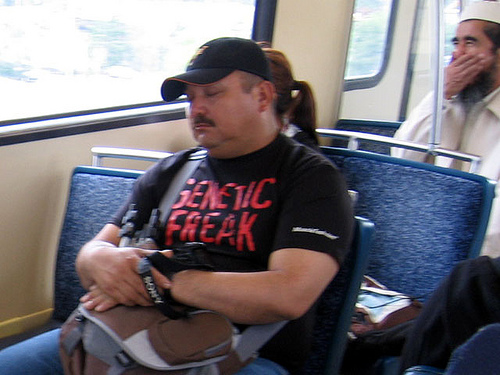

the man with the white head piece looks left down the street 


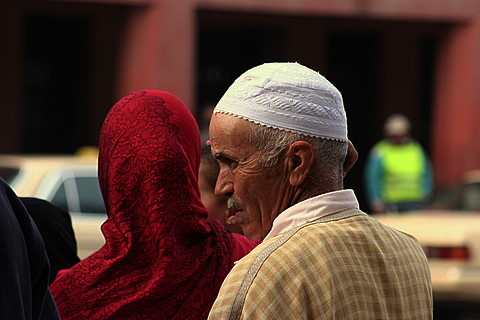

two men kickbox in a ring , one man punching the other 


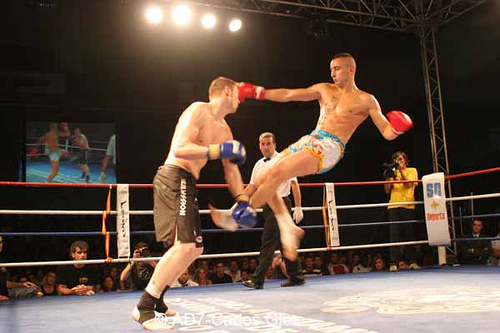

little boy standing on the bank of a river 
This image is unavailable in your country in compliance with local laws.
a dog holds a large stick in its mouth 


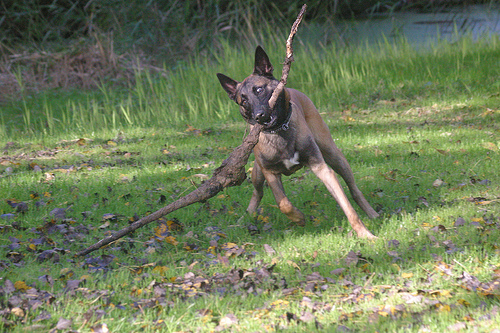

stretched image of a brown dog with a white patch of fur in his chest area sitting in the grass with trees in the background 


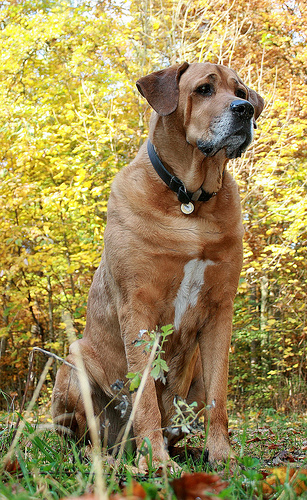

a dog jumping for a tennis ball near an ocean


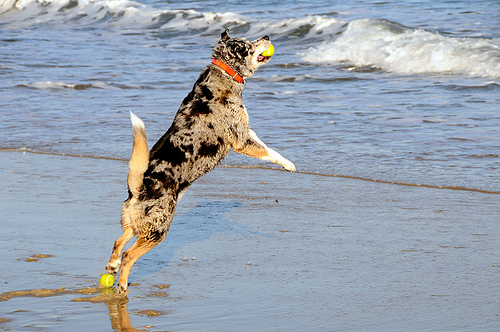

the small dog returns with his stick proudly 


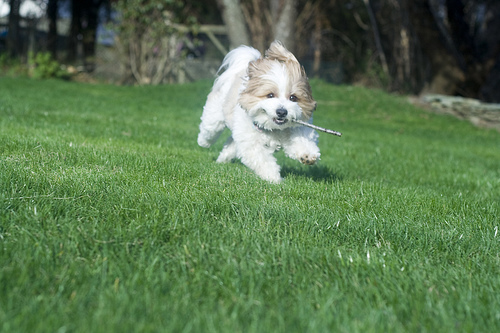

In [83]:
for query in random_query:
    print(query)
    if the_image(test_data, query) == 'This image is unavailable in your country in compliance with local laws.':
        print('This image is unavailable in your country in compliance with local laws.')
        print('====================================================================')
    else:
        img = Image.open(os.path.join("to_upload/test_images/", the_image(test_data, query))).convert('RGB')
        display(img)
        print('====================================================================')

**Я специально убрал параметр random_state у метода sample(), чтобы можно было на разных фотографиях проверить работу модели. И все фото, которые я видел, соответствовали описанию. Это даже похоже на магию, если забыть, что мы обрабатываем не рандомные картинки с интернета, а конкретные фотографии с привязанными к ним описаниями.**

## 8. Выводы

**Разработана демонстрационная версия поиска изображений по запросу. Для этого было обучено несколько моделей логистической регрессии, которые показали похожий результат**

**В ходе работы было сделано:**
* загрузка данных и их оценка. Просмотрены картинки. ID описаний очень громоздкие, и не понятен смысл делать их с привязкой к картинке
- анализ данных. Была разработана общая оценка точности описания на основе оценок экспертов и опросов. Из тренировочного датасета убраны чувствительные материалы. Отдельно отмечу, что фотографий с детьми в датасете было 75%.
- проведена векторизация картинок и текстовых описаний, затем эти векторы объединены в один
- обучены модели логистической регрессии (Ridge, Lasso, ElasticNet, LinearRegression). Метрика RMSE на тестовой выборке получилась 0.289, что оставляет желать лучшего, но все еще лучше случайного выбора. А в итоге оказалось, что для правильного выбора картинки такой точности модели достаточно.
- модель протестирована в реальных условиях. Результаты полностью соответствуют запросу. Описания соответствуют картинкам. И ни одного ребенка.

**По итогу обучения еще раз подчеркну, что не смотря на относительно небольшую точность моделей по метрике RMSE, на поиске нужных изображений они показали себя хорошо, и я думаю, что для демонстрационной версии это достойный результат. В дальнейшем, конечно, нужно улучшать и модели, и формат данных, который используется для обучения моделей.**

## 9. Чек-лист

- [x]  Jupyter Notebook открыт
- [x]  Весь код выполняется без ошибок
- [x]  Ячейки с кодом расположены в порядке исполнения
- [x]  Исследовательский анализ данных выполнен
- [x]  Проверены экспертные оценки и краудсорсинговые оценки
- [x]  Из датасета исключены те объекты, которые выходят за рамки юридических ограничений
- [x]  Изображения векторизованы
- [x]  Текстовые запросы векторизованы
- [x]  Данные корректно разбиты на тренировочную и тестовую выборки
- [x]  Предложена метрика качества работы модели
- [x]  Предложена модель схожести изображений и текстового запроса
- [x]  Модель обучена
- [x]  По итогам обучения модели сделаны выводы
- [x]  Проведено тестирование работы модели
- [x]  По итогам тестирования визуально сравнили качество поиска